In [94]:
import torch
import pandas as pd
import numpy as np
import torch.nn as nn
import matplotlib.pyplot as plt
import kagglehub
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder ,StandardScaler
from IPython.display import clear_output

In [95]:
df = pd.read_csv("/content/train.csv")
df.shape

(1460, 81)

In [96]:
df.shape

(1460, 81)

In [97]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [98]:
df.dtypes.value_counts()

,count
object,43
int64,35
float64,3


In [99]:
for col in df.columns:
  if df[col].dtypes == object:
    print(f"{col} = {df[col].nunique(dropna=False)}")

MSZoning = 5
Street = 2
Alley = 3
LotShape = 4
LandContour = 4
Utilities = 2
LotConfig = 5
LandSlope = 3
Neighborhood = 25
Condition1 = 9
Condition2 = 8
BldgType = 5
HouseStyle = 8
RoofStyle = 6
RoofMatl = 8
Exterior1st = 15
Exterior2nd = 16
MasVnrType = 4
ExterQual = 4
ExterCond = 5
Foundation = 6
BsmtQual = 5
BsmtCond = 5
BsmtExposure = 5
BsmtFinType1 = 7
BsmtFinType2 = 7
Heating = 6
HeatingQC = 5
CentralAir = 2
Electrical = 6
KitchenQual = 4
Functional = 7
FireplaceQu = 6
GarageType = 7
GarageFinish = 4
GarageQual = 6
GarageCond = 6
PavedDrive = 3
PoolQC = 4
Fence = 5
MiscFeature = 5
SaleType = 9
SaleCondition = 6


### split train & test

In [100]:
X = df.drop(columns=["SalePrice","Id"],errors="ignore")
y = df["SalePrice"]

In [101]:
X_train ,X_val ,y_train ,y_val = train_test_split(
    X ,y , test_size = 0.2 ,random_state = 42
)
print("X_train shape:", X_train.shape)
print("X_val shape:  ", X_val.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:  ", y_val.shape)

X_train shape: (1168, 79)
X_val shape:   (292, 79)
y_train shape: (1168,)
y_val shape:   (292,)


In [102]:
quality_cols = [
    "ExterQual",
    "ExterCond",
    "BsmtQual",
    "BsmtCond",
    "HeatingQC",
    "KitchenQual",
    "FireplaceQu",
    "GarageQual",
    "GarageCond",
    "PoolQC",

]
for col in quality_cols:
  print(f"{col} -> {df[col].unique()}")

ExterQual -> ['Gd' 'TA' 'Ex' 'Fa']
ExterCond -> ['TA' 'Gd' 'Fa' 'Po' 'Ex']
BsmtQual -> ['Gd' 'TA' 'Ex' nan 'Fa']
BsmtCond -> ['TA' 'Gd' nan 'Fa' 'Po']
HeatingQC -> ['Ex' 'Gd' 'TA' 'Fa' 'Po']
KitchenQual -> ['Gd' 'TA' 'Ex' 'Fa']
FireplaceQu -> [nan 'TA' 'Gd' 'Fa' 'Ex' 'Po']
GarageQual -> ['TA' 'Fa' 'Gd' nan 'Ex' 'Po']
GarageCond -> ['TA' 'Fa' nan 'Gd' 'Po' 'Ex']
PoolQC -> [nan 'Ex' 'Fa' 'Gd']


In [103]:
X_train[quality_cols] = X_train[quality_cols].fillna("None")
X_val[quality_cols] = X_val[quality_cols].fillna("None")

In [104]:
qual_map = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "None": 0}

X_train[quality_cols] = X_train[quality_cols].replace(qual_map)
X_val[quality_cols] = X_val[quality_cols].replace(qual_map)

/tmp/ipykernel_6522/3888512015.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train[quality_cols] = X_train[quality_cols].replace(qual_map)
/tmp/ipykernel_6522/3888512015.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_val[quality_cols] = X_val[quality_cols].replace(qual_map)


In [105]:
X_train[quality_cols].head()

,ExterQual,ExterCond,BsmtQual,BsmtCond,HeatingQC,KitchenQual,FireplaceQu,GarageQual,GarageCond,PoolQC
254,3,4,3,3,3,3,0,3,3,0
1066,4,3,4,3,4,3,3,3,3,0
638,3,3,2,3,4,3,0,0,0,0
799,3,3,4,3,5,4,3,3,3,0
380,3,3,3,3,3,4,4,3,3,0


In [106]:
X_val[quality_cols].isna().sum()

,0
ExterQual,0
ExterCond,0
BsmtQual,0
BsmtCond,0
HeatingQC,0
KitchenQual,0
FireplaceQu,0
GarageQual,0
GarageCond,0
PoolQC,0


In [107]:
X_train[quality_cols].isna().sum()

,0
ExterQual,0
ExterCond,0
BsmtQual,0
BsmtCond,0
HeatingQC,0
KitchenQual,0
FireplaceQu,0
GarageQual,0
GarageCond,0
PoolQC,0


In [108]:
special_ordinal_cols = [
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "GarageFinish",
    "Functional",
    "PavedDrive",
    "LandSlope",
    "LotShape",
    "CentralAir"
]
X_train[special_ordinal_cols] = X_train[special_ordinal_cols].fillna("None")
X_val[special_ordinal_cols] = X_val[special_ordinal_cols].fillna("None")

In [109]:
special_mappings = {
    "BsmtExposure": {"Gd": 4, "Av": 3, "Mn": 2, "No": 1, "None": 0},
    "BsmtFinType1": {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1, "None": 0},
    "BsmtFinType2": {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1, "None": 0},
    "GarageFinish": {"Fin": 3, "RFn": 2, "Unf": 1, "None": 0},
    "Functional": {"Typ": 7, "Min1": 6, "Min2": 5, "Mod": 4, "Maj1": 3, "Maj2": 2, "Sev": 1, "Sal": 0, "None": 0},
    "PavedDrive": {"Y": 2, "P": 1, "N": 0, "None": 0},
    "LandSlope": {"Gtl": 2, "Mod": 1, "Sev": 0, "None": 0},
    "LotShape": {"Reg": 3, "IR1": 2, "IR2": 1, "IR3": 0, "None": 0},
    "CentralAir": {"Y": 1, "N": 0, "None": 0}
}

X_train = X_train.replace(special_mappings)
X_val = X_val.replace(special_mappings)

/tmp/ipykernel_6522/2294515621.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train = X_train.replace(special_mappings)
/tmp/ipykernel_6522/2294515621.py:14: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_val = X_val.replace(special_mappings)


In [110]:
nominal_cols=X_train.select_dtypes(include=["object"]).columns.tolist()
print(nominal_cols)
print(len(nominal_cols))

['MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'Electrical', 'GarageType', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']
24


In [111]:
missing_nominal = X_train[nominal_cols].isna().sum()
print(missing_nominal[missing_nominal > 0])

Alley          1094
MasVnrType      683
Electrical        1
GarageType       64
Fence           935
MiscFeature    1122
dtype: int64


In [112]:
none_cols = ["Alley", "Fence", "MiscFeature", "GarageType", "MasVnrType"]
X_train[none_cols] = X_train[none_cols].fillna("None")
X_val[none_cols] = X_val[none_cols].fillna("None")

In [113]:
electrical_mode = X_train["Electrical"].mode()[0]
X_train["Electrical"] = X_train["Electrical"].fillna(electrical_mode)
X_val["Electrical"] = X_val["Electrical"].fillna(electrical_mode)

In [114]:
X_train[nominal_cols].isna().sum()

,0
MSZoning,0
Street,0
Alley,0
LandContour,0
Utilities,0
LotConfig,0
Neighborhood,0
Condition1,0
Condition2,0
BldgType,0


In [115]:
encoder = OneHotEncoder(handle_unknown= "ignore" , sparse_output= False)
encoder.set_output(transform="pandas")

OneHotEncoder(handle_unknown='ignore', sparse_output=False)

In [116]:
X_train_encode = encoder.fit_transform(X_train[nominal_cols])
X_val_encode = encoder.transform(X_val[nominal_cols])

In [117]:
X_train = X_train.drop(columns= nominal_cols)
X_train = pd.concat([X_train,X_train_encode],axis = 1)

X_val = X_val.drop(columns= nominal_cols)
X_val = pd.concat([X_val,X_val_encode], axis = 1)

In [118]:
print("X_train shape after One-Hot:", X_train.shape)
print("X_val shape after One-Hot:  ", X_val.shape)

X_train shape after One-Hot: (1168, 227)
X_val shape after One-Hot:   (292, 227)


In [119]:
int_df = df.select_dtypes(include=["int64"]).columns.tolist()
int_df.remove("SalePrice")
int_df.pop(0)
int_df

['MSSubClass',
 'LotArea',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'TotRmsAbvGrd',
 'Fireplaces',
 'GarageCars',
 'GarageArea',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 '3SsnPorch',
 'ScreenPorch',
 'PoolArea',
 'MiscVal',
 'MoSold',
 'YrSold']

In [120]:
float_df = df.select_dtypes(include="float64").columns.tolist()
float_df

['LotFrontage', 'MasVnrArea', 'GarageYrBlt']

In [121]:
X_train[int_df].isna().sum().sum()

np.int64(0)

In [122]:
X_val[int_df].isna().sum().sum()

np.int64(0)

In [123]:
print(X_train[float_df].isna().sum())
print(X_val[float_df].isna().sum())

LotFrontage    217
MasVnrArea       6
GarageYrBlt     64
dtype: int64
LotFrontage    42
MasVnrArea      2
GarageYrBlt    17
dtype: int64


In [124]:
X_train["MasVnrArea"] = X_train["MasVnrArea"].fillna(0.0)
X_val["MasVnrArea"] = X_val["MasVnrArea"].fillna(0.0)

In [125]:
for col in ["LotFrontage", "GarageYrBlt"]:
    median_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_val)
    X_val[col] = X_val[col].fillna(median_val)

In [126]:
print("Total NaNs in X_train:", X_train.isna().sum().sum())
print("Total NaNs in X_val:", X_val.isna().sum().sum())

Total NaNs in X_train: 0
Total NaNs in X_val: 0


In [127]:
cols_to_scale = int_df + float_df + quality_cols + special_ordinal_cols
cols_to_scale = [col for col in cols_to_scale if col in X_train.columns]

In [128]:
scaler = StandardScaler()
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_val[cols_to_scale] = scaler.transform(X_val[cols_to_scale])

In [129]:
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)

In [130]:
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_log.values, dtype=torch.float32).view(-1, 1)

X_val_tensor = torch.tensor(X_val.values, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_log.values, dtype=torch.float32).view(-1, 1)

print("X_train_tensor shape:", X_train_tensor.shape)
print("y_train_tensor shape:", y_train_tensor.shape)

X_train_tensor shape: torch.Size([1168, 227])
y_train_tensor shape: torch.Size([1168, 1])


In [131]:
input_dim = X_train_tensor.shape[1]
model_base = nn.Sequential(
    nn.Linear(input_dim , 128),
    nn.ReLU(),
    nn.Linear(128,64),
    nn.ReLU(),
    nn.Linear(64,32),
    nn.ReLU(),
    nn.Linear(32,1)
)

In [132]:
criterion = nn.MSELoss()
optimizer_base = torch.optim.AdamW(model_base.parameters(),lr=0.001,weight_decay=1e-2)

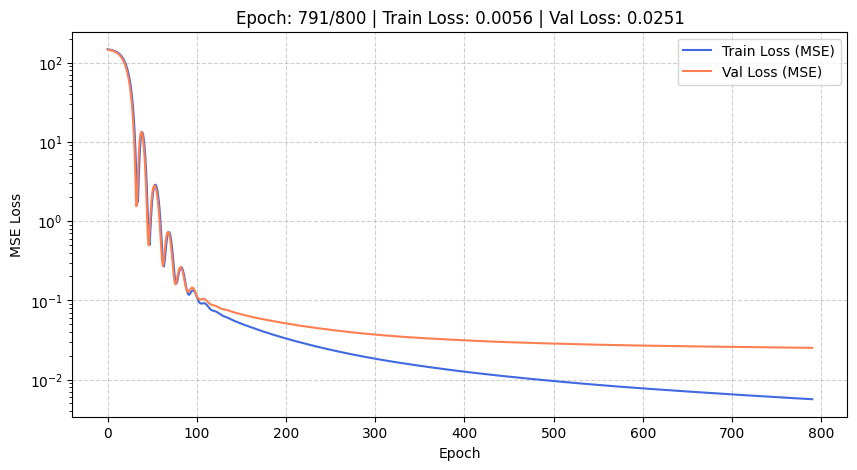

In [133]:
n_epoch = 800
losses_train = []
losses_val = []

for epoch in range(n_epoch):
  model_base.train()
  #zero grad
  optimizer_base.zero_grad()

  #forward
  output = model_base(X_train_tensor)
  loss = criterion(output,y_train_tensor)

  losses_train.append(loss.item())

  #bacward
  loss.backward()
  optimizer_base.step()

  # evaluation
  model_base.eval()
  with torch.no_grad():
    output_eval = model_base(X_val_tensor)
    loss_val = criterion(output_eval,y_val_tensor)
    losses_val.append(loss_val.item())

  if epoch % 10 == 0:
    clear_output(wait=True)

    plt.figure(figsize=(10,5))
    plt.plot(losses_train, label="Train Loss (MSE)", color="royalblue")
    plt.plot(losses_val, label="Val Loss (MSE)", color="coral")
    plt.title(
        f"Epoch: {epoch + 1}/{n_epoch} | Train Loss: {loss.item():.4f} | Val"
        f" Loss: {loss_val.item():.4f}"
    )
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.yscale("log")  # مقیاس لگاریتمی برای دیدن جزئیات دقیق کاهش خطا
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.show()

In [134]:
# plt.plot(losses_val[350:])

In [135]:
# plt.plot(losses_train[350:])

In [136]:
#with drop out

In [178]:
input_dim = X_train_tensor.shape[1]
model_dropout = nn.Sequential(
    nn.Linear(input_dim, 128),
    nn.LayerNorm(128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.LayerNorm(64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.LayerNorm(32),
    nn.ReLU(),
    nn.Linear(32, 1),
)

In [179]:
with torch.no_grad():
  model_dropout[-1].bias.fill_(y_train_tensor.mean())
optimizer_dropout = torch.optim.AdamW(model_dropout.parameters(), lr=0.001, weight_decay=0.01)

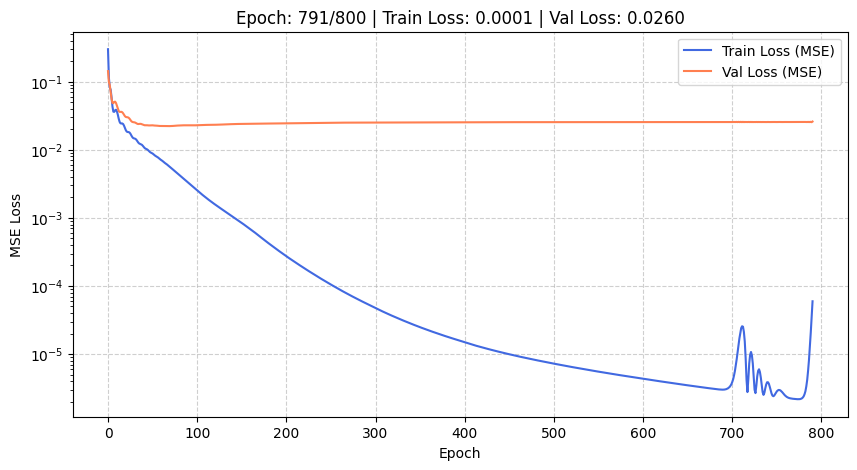

In [180]:
n_epoch = 800
losses_train_dropout = []
losses_val_dropout = []



for epoch in range(n_epoch):
  model_dropout.train()
  #zero grad
  optimizer_dropout.zero_grad()
  #forward
  output = model_dropout(X_train_tensor)
  loss = criterion(output,y_train_tensor)

  losses_train_dropout.append(loss.item())

  #bacward
  loss.backward()
  optimizer_dropout.step()

  # evaluation
  model_dropout.eval()
  with torch.no_grad():
    output_eval = model_dropout(X_val_tensor)
    loss_val = criterion(output_eval,y_val_tensor)
    losses_val_dropout.append(loss_val.item())

  if epoch % 10 == 0:
    clear_output(wait=True)

    plt.figure(figsize=(10,5))
    plt.plot(losses_train_dropout, label="Train Loss (MSE)", color="royalblue")
    plt.plot(losses_val_dropout, label="Val Loss (MSE)", color="coral")
    plt.title(
        f"Epoch: {epoch + 1}/{n_epoch} | Train Loss: {loss.item():.4f} | Val"
        f" Loss: {loss_val.item():.4f}"
    )
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.yscale("log")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.show()

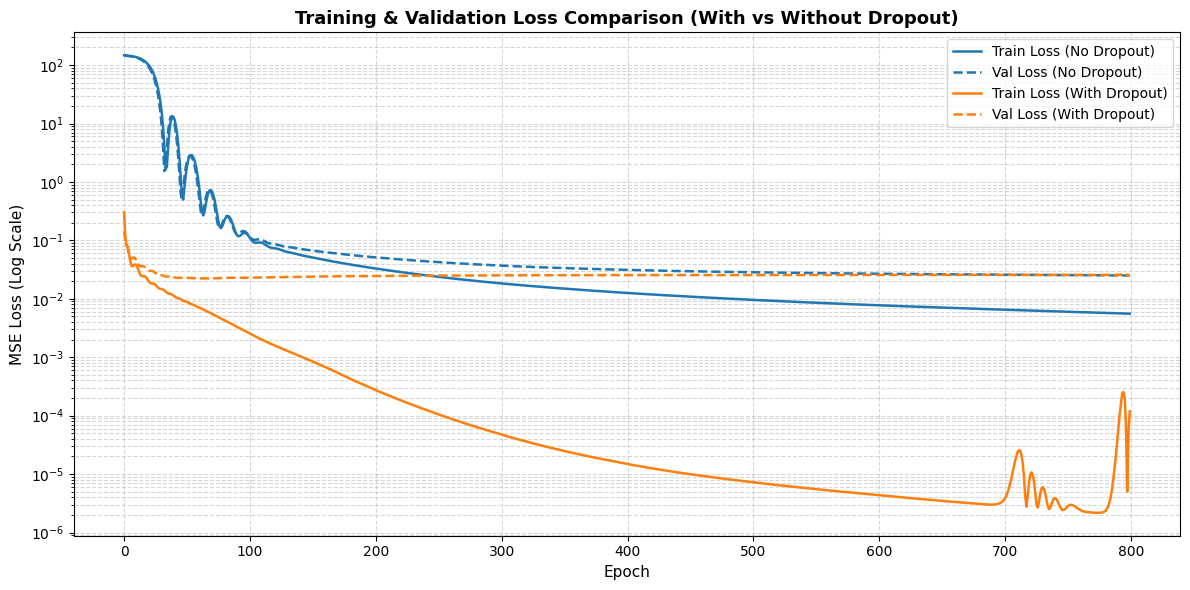

In [181]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# منحنی‌های مدل بدون دراپ‌اوت (مدل پایه)
plt.plot(
    losses_train,
    label="Train Loss (No Dropout)",
    color="#1f77b4",
    linewidth=1.8,
)
plt.plot(
    losses_val,
    label="Val Loss (No Dropout)",
    color="#1f77b4",
    linestyle="--",
    linewidth=1.8,
)

# منحنی‌های مدل دارای دراپ‌اوت
plt.plot(
    losses_train_dropout,
    label="Train Loss (With Dropout)",
    color="#ff7f0e",
    linewidth=1.8,
)
plt.plot(
    losses_val_dropout,
    label="Val Loss (With Dropout)",
    color="#ff7f0e",
    linestyle="--",
    linewidth=1.8,
)

plt.title(
    "Training & Validation Loss Comparison (With vs Without Dropout)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("MSE Loss (Log Scale)", fontsize=11)

# مقیاس لگاریتمی برای مشاهده واضح انحراف‌های انتهایی و مقایسه Overfitting
plt.yscale("log")

plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend(fontsize=10, loc="upper right")
plt.tight_layout()
plt.show()